<a href="https://colab.research.google.com/github/DipaliKhochare/Website_Health_Monitor/blob/main/website_health_monitor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
%%writefile monitor.py
import socket, ssl, time, requests
from datetime import datetime, timezone

def check(domain):
    result = {"domain": domain}
    try:
        result["ip"] = socket.gethostbyname(domain)               # DNS
        with socket.create_connection((domain, 443), timeout=5) as sock:  # TCP
            ctx = ssl.create_default_context()
            with ctx.wrap_socket(sock, server_hostname=domain) as s:      # TLS
                cert = s.getpeercert()
                exp = datetime.strptime(cert["notAfter"], "%b %d %H:%M:%S %Y %Z")
                result["cert_days_left"] = (exp - datetime.utcnow()).days
        start = time.time()
        r = requests.get(f"https://{domain}", timeout=5)          # HTTP
        result["status"] = r.status_code
        result["latency_ms"] = round((time.time() - start) * 1000)
    except Exception as e:
        result["error"] = str(e)
    return result

if __name__ == "__main__":
    with open("sites.txt") as f:
        for line in f:
            if line.strip():
                print(datetime.now(timezone.utc).isoformat(), check(line.strip()))

Overwriting monitor.py


In [29]:
%%writefile sites.txt
google.com
github.com
example.com

Overwriting sites.txt


In [30]:
%%writefile run.sh
#!/bin/bash
mkdir -p logs
python3 monitor.py >> logs/health.log 2>&1

Overwriting run.sh


In [31]:
!chmod +x run.sh

In [32]:
!./run.sh

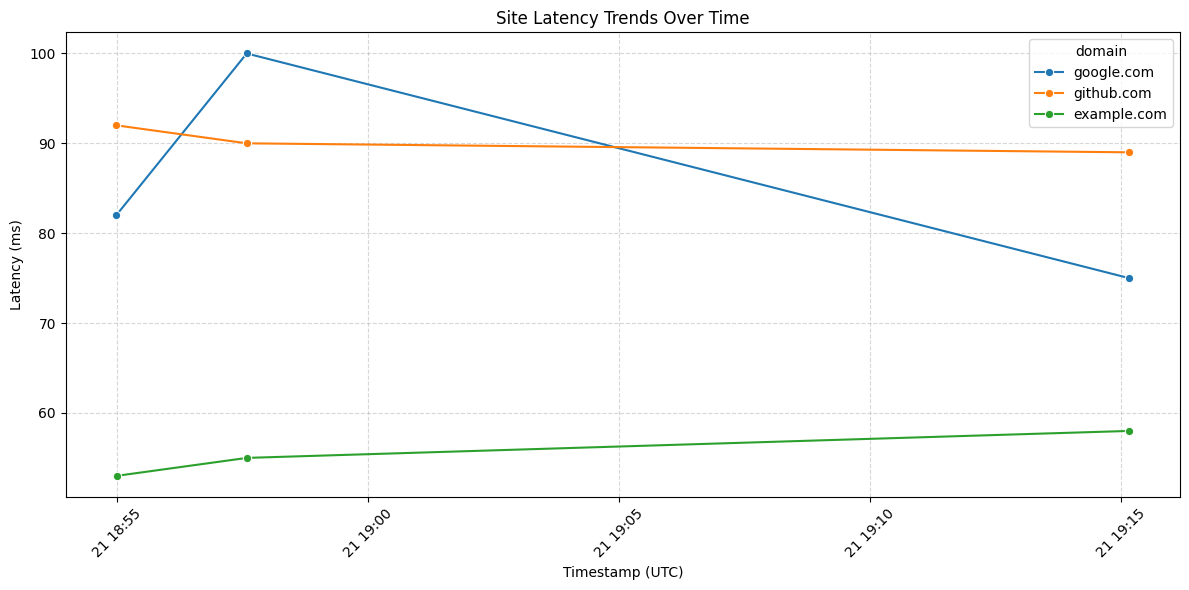

In [34]:
import re
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

log_file_path = 'logs/health.log'
data = []

# Regex to extract timestamp and the dictionary representation of health check results
log_pattern = re.compile(r'^(\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}\.\d+\+00:00)\s+(\{.*\})$')

with open(log_file_path, 'r') as f:
    for line in f:
        match = log_pattern.match(line.strip())
        if match:
            timestamp_str, json_str = match.groups()
            try:
                # Convert single quotes to double quotes for valid JSON parsing
                json_str_fixed = json_str.replace("'", '"')
                record = json.loads(json_str_fixed)
                if 'latency_ms' in record:
                    data.append({
                        'timestamp': pd.to_datetime(timestamp_str),
                        'domain': record['domain'],
                        'latency_ms': record['latency_ms']
                    })
            except Exception:
                continue

if data:
    df = pd.DataFrame(data)

    plt.figure(figsize=(12, 6))
    sns.lineplot(data=df, x='timestamp', y='latency_ms', hue='domain', marker='o')
    plt.title('Site Latency Trends Over Time')
    plt.xlabel('Timestamp (UTC)')
    plt.ylabel('Latency (ms)')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No valid health logs found to visualize. Make sure you have successfully run the monitor script first!")